# Mortgage Prepayment (CPR) & Default (CDR) Competing Risks

A mortgage can leave a pool in two ways: the borrower refinances or sells and pays it off early, or stops paying. Each outcome rules out the other, and treating them separately overstates both. For an investor in mortgage bonds, the timing of these two events decides when the money comes back. This notebook models them together on 500,000 real loans from two very different periods: the 2005–08 vintages that went through the housing crisis and the 2018–23 vintages that went through the pandemic refinancing boom.

**What it does.** It measures and models the two ways a mortgage leaves a securitised pool, voluntary prepayment and default, on 200,000 Fannie Mae loans originated in 2005–08 and 300,000 Freddie Mac loans originated in 2018–23.

It computes pool CPR and CDR by vintage, draws the refinancing S-curve for four periods (before, during and after the crisis, and since 2018), and estimates cumulative incidence with the Aalen–Johansen estimator, showing how much the naive Kaplan–Meier overstates each risk.

It then fits cause-specific monthly hazard models (a GLM with seasoning, incentive, burnout and seasonality, and a multiclass LightGBM), back-tests them out of time on pool-level CPR and CDR, and projects pool prepayment speeds under ±100 bp mortgage-rate scenarios.

**Data.** Fannie Mae Single-Family Loan Performance data (2005–2008 acquisitions) and the Freddie Mac Single-Family Loan-Level Dataset (vintages 2018–2023), monthly performance to March 2026, and Freddie Mac's 30-year mortgage rate survey (FRED).

**Methods.** SMM/CPR and MDR/CDR, Aalen–Johansen cumulative incidence against 1 − Kaplan–Meier, discrete-time cause-specific logistic hazards, a LightGBM multiclass hazard, an out-of-time pool back-test and a rate-shock projection.

**Key output.** CPR and CDR history by vintage, the S-curve by period, competing-risk incidence curves, model accuracy out of time, and projected speeds under rate shocks.

## 1. Why prepayment and default are one problem

An MBS or ABS investor, and a lender who funds a mortgage book, care about **when** principal comes back. Prepayment returns it early (bad for a premium bond, good for a discount bond); default returns it late and short. The two are **competing risks**: a loan that prepays can no longer default, and vice versa, so each must be modelled with the other in mind.

- **SMM** (single monthly mortality) = prepaid principal / scheduled balance; **CPR** $=1-(1-\text{SMM})^{12}$. **MDR** and **CDR** are the default equivalents.
- **Kaplan–Meier** treats the competing event as censoring and estimates the risk "in a world where the other event cannot happen", so $1-\hat S_{KM}$ *overstates* the probability of each event. The **Aalen–Johansen** estimator gives the cumulative incidence function $F_k(t)=P(T\le t,\ \text{cause}=k)$ that actually applies.
- Prepayment drivers: the **refinancing incentive** (note rate minus market rate) through an S-shaped response, **seasoning** (speeds ramp up over the first 2–3 years), **burnout** (borrowers who have ignored past incentives keep ignoring them), housing turnover and seasonality, and loan size (refinancing costs are partly fixed).

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import duckdb
import lightgbm as lgb

# lifelines jitters tied monthly times itself
warnings.filterwarnings("ignore", message="Tied event times")
import statsmodels.api as sm
from lifelines import AalenJohansenFitter, KaplanMeierFitter
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 12
HAZARD_SAMPLE = 10  # 1 in 10 loans enter the loan-month panel
OOT_START = 202401  # train before 2024, test 2024-01 → latest
RATE_SHOCKS_BP = [-100, 0, 100]

print(
    f"duckdb {duckdb.__version__} · lightgbm {lgb.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

duckdb 1.5.6 · lightgbm 4.7.0 · run on 2026-10-28


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


# --- Freddie Mac Single-Family Loan-Level Dataset (sample files)
# Download manually (free registration, non-commercial licence):
# https://freddiemac.embs.com/FLoan/Data/download.php
# → "Sample Dataset" → sample_YYYY.zip, saved in data/freddie_mac/ at the repo
# root.
# The files are licensed and are never committed: data/ is in .gitignore.
import zipfile


def find_shared_data(name):
    """
    Find data/<name> in this project's folder or any folder above it, up to the
    repo root (works with sub-folders).
    """
    for d in [PROJECT_DIR, *PROJECT_DIR.parents]:
        if (d / "data" / name).exists():
            return d / "data" / name
        if (d / ".git").exists():
            break
    return None


FREDDIE_DIR = find_shared_data("freddie_mac")
if FREDDIE_DIR is None or not list(FREDDIE_DIR.glob("sample_*.zip")):
    raise FileNotFoundError(
        "Put the Freddie Mac sample_YYYY.zip files in FIN/data/freddie_mac/"
        " (see the link above)."
    )
FM_TXT = DATA_DIR / "freddie_txt"
FM_TXT.mkdir(exist_ok=True)
for z in sorted(FREDDIE_DIR.glob("sample_*.zip")):
    with zipfile.ZipFile(z) as f:
        for m in f.namelist():
            if not (FM_TXT / m).exists():
                f.extract(m, FM_TXT)
VINTAGES = sorted(int(p.stem[-4:]) for p in FM_TXT.glob("sample_orig_*.txt"))

ORIG_COLS = [
    "credit_score",
    "first_pay_date",
    "first_time_buyer",
    "maturity_date",
    "msa",
    "mi_pct",
    "n_units",
    "occupancy",
    "cltv",
    "dti",
    "orig_upb",
    "ltv",
    "orig_rate",
    "channel",
    "ppm_flag",
    "amort_type",
    "state",
    "prop_type",
    "zip3",
    "loan_id",
    "purpose",
    "orig_term",
    "n_borrowers",
    "seller_servicer",
    "super_conforming",
    "pre_relief_id",
    "program",
    "relief_refi",
    "valuation_method",
    "io_flag",
    "mi_cancel",
]
PERF_COLS = {
    0: "loan_id",
    1: "period",
    2: "upb",
    3: "dq",
    4: "age",
    5: "months_left",
    7: "mod_flag",
    8: "zb_code",
    9: "zb_date",
    10: "rate",
    21: "actual_loss",
    25: "eltv",
    26: "zb_upb",
    29: "assistance",
}


def freddie_con():
    con = duckdb.connect(
        str(DATA_DIR / "freddie.duckdb")
    )  # tables on disk, not in the notebook's memory
    con.execute("SET enable_progress_bar = false")
    con.execute("SET memory_limit = '2GB'")
    orig_sel = ", ".join(
        f"column{i:02d} AS {c}" for i, c in enumerate(ORIG_COLS)
    )
    con.execute(
        f"""CREATE OR REPLACE VIEW orig AS SELECT {orig_sel}
                    FROM read_csv('{(FM_TXT / "sample_orig_*.txt").as_posix()}', delim='|', header=false, all_varchar=true)"""
    )
    perf_sel = ", ".join(f"column{i:02d} AS {c}" for i, c in PERF_COLS.items())
    con.execute(
        f"""CREATE OR REPLACE VIEW perf AS SELECT {perf_sel}
                    FROM read_csv('{(FM_TXT / "sample_perf_*.txt").as_posix()}', delim='|', header=false, all_varchar=true)"""
    )
    return con


# --- Fannie Mae Single-Family Loan Performance data, 2005-2008 acquisitions
# Download manually (free registration): https://capitalmarkets.fanniemae.com
# → Single-Family Loan Performance Data → quarterly files 2005Q1 ... 2008Q4,
# saved as data/fannie_mae/2005Q1.zip ... at the repo root. The first run
# builds a sample in the Freddie Mac sample format (12,500 loans per quarter,
# 50,000 per vintage, monthly history) in data/fannie_mae/sample/ and reuses
# it afterwards. The files are licensed and are never committed.
import random


def _ym(s):
    return s[2:] + s[:2] if len(s) == 6 else ""


def _num(s, d=0.0):
    try:
        return float(s)
    except ValueError:
        return d


def fannie_quarter_to_sample(zip_path, yy, q, out_dir, keep=12_500,
                             share=0.08):
    """Filter one quarterly file (loan id mod 1000 < 80), draw `keep` loans
    and append them to sample_orig_20yy.txt / sample_perf_20yy.txt."""
    with zipfile.ZipFile(zip_path) as zf:
        name = zf.namelist()[0]
        lines = []
        with zf.open(name) as f:
            for raw in f:
                line = raw.decode("latin-1")
                lid = line.split("|", 3)[1]
                if int(lid) % 1000 < share * 1000:
                    lines.append(line)
    ids, seen = [], set()
    for line in lines:
        i = line.split("|", 3)[1]
        if i not in seen:
            seen.add(i)
            ids.append(i)
    random.seed(int(f"20{yy}{q}"))
    chosen = set(random.sample(ids, min(keep, len(ids))))
    new_id = {i: f"F{yy}Q{q}{k:07d}" for k, i in enumerate(sorted(chosen))}
    fo = open(out_dir / f"sample_orig_20{yy}.txt", "a")
    fp = open(out_dir / f"sample_perf_20{yy}.txt", "a")
    done, last_age = set(), {}
    for line in lines:
        x = line.rstrip("\n").split("|")
        lid = x[1]
        if lid not in chosen:
            continue
        p = lambda k: x[k - 1] if k - 1 < len(x) else ""
        nid = new_id[lid]
        if lid not in done:
            done.add(lid)
            purpose = {"P": "P", "C": "C", "R": "N"}.get(p(27), "9")
            o = [p(24) or "9999", _ym(p(15)),
                 p(26) if p(26) in ("Y", "N") else "9", _ym(p(19)), p(32),
                 p(34) or "0", p(29), p(30), p(21) or "999", p(23) or "999",
                 str(int(_num(p(10)))), p(20) or "999", p(8), p(4) or "9",
                 p(36) or "N", p(35) or "FRM", p(31), p(28), p(33), nid,
                 purpose, p(13), p(22) or "99", (p(5) or "OTHER").upper(),
                 p(87) or "N", "", p(79), p(103) or "N", p(86) or "9",
                 p(37) or "N", p(43) or "9999"]
            fo.write("|".join(o) + "\n")
        per, zb, upb = _ym(p(3)), p(44), _num(p(12))
        age = int(_num(p(16), -1))
        if age < 0:
            age = last_age.get(lid, -1) + 1
        last_age[lid] = age
        if upb == 0 and not zb:         # masked in the first months
            upb = _num(p(11)) or _num(p(10))
        loss = ""
        if p(59) or p(60) or p(62):     # disposition: Freddie-style loss
            zbu, rate = _num(p(46)), _num(p(9)) or _num(p(8))
            lp, zd = _ym(p(51)), _ym(p(45)) or per
            gap = ((int(zd[:4]) - int(lp[:4])) * 12 + int(zd[4:])
                   - int(lp[4:])) if lp and zd else 0
            dai = zbu * rate / 1200 * max(gap - 1, 0)
            costs = sum(_num(p(k)) for k in (54, 55, 56, 57, 58))
            proceeds = sum(_num(p(k)) for k in (59, 60, 61, 62))
            loss = f"{proceeds - zbu - costs - dai:.2f}"
        r = [""] * 35
        r[0], r[1], r[2] = nid, per, f"{0.0 if zb else upb:.2f}"
        r[3] = "" if p(40) == "XX" else p(40)
        r[4], r[5] = str(age), p(18)
        r[7] = "Y" if p(42) == "Y" else ""
        r[8], r[9], r[10] = zb, _ym(p(45)), p(9) or p(8)
        r[11], r[12] = p(63) or "0.00", _ym(p(51))
        r[21], r[26], r[29] = loss, (p(46) if zb else ""), p(102)
        r[31] = f"{_num(p(110)) or (0.0 if zb else upb):.2f}"
        r[33] = (p(6) or "OTHER").upper()
        fp.write("|".join(r) + "\n")
    fo.close()
    fp.close()


def fannie_sample_zips():
    src = find_shared_data("fannie_mae")
    if src is None:
        return []
    out = src / "sample"
    if not list(out.glob("sample_*.zip")):
        quarters = sorted(src.glob("20??Q?.zip"))
        if not quarters:
            return []
        out.mkdir(exist_ok=True)
        tmp = DATA_DIR / "fannie_build"
        tmp.mkdir(exist_ok=True)
        for z in quarters:              # about 1-2 minutes per quarter
            print("sampling", z.name)
            fannie_quarter_to_sample(z, z.stem[2:4], z.stem[-1], tmp)
        for y in sorted({z.stem[:4] for z in quarters}):
            with zipfile.ZipFile(out / f"sample_{y}.zip", "w",
                                 zipfile.ZIP_DEFLATED) as zf:
                for kind in ["orig", "perf"]:
                    zf.write(tmp / f"sample_{kind}_{y}.txt",
                             f"sample_{kind}_{y}.txt")
    return sorted(out.glob("sample_*.zip"))


for z in fannie_sample_zips():
    with zipfile.ZipFile(z) as f:
        for m in f.namelist():
            if not (FM_TXT / m).exists():
                f.extract(m, FM_TXT)
VINTAGES = sorted(int(p.stem[-4:]) for p in FM_TXT.glob("sample_orig_*.txt"))


## 3. Pool speeds by vintage

Prepayment is a voluntary payoff (zero-balance code 01). Default is defined as 90+ days delinquent outside a COVID forbearance plan, or a credit-event termination. Speeds are computed on balances: prepaid (or defaulted) unpaid balance divided by the balance outstanding at the start of the month.

In [3]:
con = freddie_con()
con.execute("""
CREATE OR REPLACE TABLE p AS
SELECT loan_id, CAST(period AS INT) AS per, CAST(age AS INT) AS age, TRY_CAST(upb AS DOUBLE) AS upb, dq, zb_code,
       COALESCE(assistance, '') AS assistance, TRY_CAST(zb_upb AS DOUBLE) AS zb_upb,
       2000 + CAST(substr(loan_id, 2, 2) AS INT) AS vintage
FROM perf""")
con.execute(
    """
CREATE OR REPLACE TABLE first_def AS
SELECT loan_id, MIN(per) AS d_per FROM p
WHERE (dq NOT IN ('00', '01', '02', 'RA') AND assistance <> 'F') OR zb_code IN ('02', '03', '09', '15') GROUP BY 1"""
)
pool = con.execute("""
WITH m AS (
    SELECT p.vintage, p.per, p.loan_id, p.age,
           COALESCE(LAG(p.upb) OVER (PARTITION BY p.loan_id ORDER BY p.per), p.upb) AS bal_start,
           CASE WHEN p.zb_code = '01' THEN COALESCE(p.zb_upb, LAG(p.upb) OVER (PARTITION BY p.loan_id ORDER BY p.per)) ELSE 0 END AS prepaid,
           CASE WHEN f.d_per = p.per THEN COALESCE(LAG(p.upb) OVER (PARTITION BY p.loan_id ORDER BY p.per), p.upb) ELSE 0 END AS defaulted
    FROM p LEFT JOIN first_def f USING (loan_id)
    WHERE f.d_per IS NULL OR p.per <= f.d_per)
SELECT vintage, per, SUM(bal_start) AS bal, SUM(prepaid) AS prepaid, SUM(defaulted) AS defaulted, COUNT(*) AS loans
FROM m GROUP BY 1, 2 ORDER BY 1, 2""").df()
pool["smm"] = pool["prepaid"] / pool["bal"]
pool["mdr"] = pool["defaulted"] / pool["bal"]
pool["CPR %"] = (1 - (1 - pool["smm"]) ** 12) * 100
pool["CDR %"] = (1 - (1 - pool["mdr"]) ** 12) * 100
pool["date"] = pd.to_datetime(pool["per"].astype(str), format="%Y%m")
mort = (
    fred.get_series("MORTGAGE30US", observation_start="2004-01-01")
    .resample("MS")
    .mean()
)
summary = (
    pool.assign(year=pool["date"].dt.year)
    .groupby(["vintage", "year"])
    .apply(
        lambda g: pd.Series({
            "CPR %": (
                1 - (1 - g["prepaid"].sum() / g["bal"].sum()) ** 12
            ) * 100,
            "CDR %": (
                1 - (1 - g["defaulted"].sum() / g["bal"].sum()) ** 12
            ) * 100,
        }),
        include_groups=False,
    )
)
summary["CDR %"].unstack().loc[2005:2008, 2006:2014].round(1).pipe(display)
summary["CPR %"].unstack().round(1)

year,2006,2007,2008,2009,2010,2011,2012,2013,2014
vintage,,,,,,,,,
2005,0.40,0.80,1.80,4.10,4.20,3.50,3.70,3.10,2.00
2006,0.20,0.90,2.60,7.20,7.00,5.90,4.90,4.50,3.30
2007,NaN,0.40,2.40,7.90,7.60,6.20,5.50,4.50,3.70
2008,NaN,NaN,0.80,3.70,4.70,4.50,4.60,3.80,3.10


year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
vintage,,,,,,,,,,,,,,,,,,,,,
2005,6.70,7.90,8.20,7.10,15.30,18.70,18.60,30.40,32.60,17.80,...,15.60,10.20,11.00,15.20,17.30,11.50,6.20,5.60,7.00,3.90
2006,NaN,6.60,10.00,12.90,24.70,19.90,19.20,32.00,38.10,21.80,...,16.70,13.50,10.70,12.50,15.70,11.40,5.70,5.90,5.30,5.70
2007,NaN,NaN,5.30,11.10,24.50,21.30,19.10,33.30,39.30,21.70,...,18.00,14.10,10.90,14.00,17.40,11.90,7.20,4.40,6.70,8.20
2008,NaN,NaN,NaN,4.60,25.40,27.30,24.50,37.40,40.60,21.00,...,16.00,12.70,9.60,15.20,19.60,12.50,7.20,4.60,4.80,3.70
2018,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,3.10,21.50,43.80,43.10,17.50,6.30,6.40,5.60,4.60
2019,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,11.50,35.80,41.70,14.10,5.40,5.40,5.50,4.70
2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,13.60,19.60,7.50,4.10,4.00,4.20,3.30
2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,4.50,4.60,3.50,3.80,4.10,3.30
2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,2.40,3.80,5.30,6.60,7.10


### The S-curve

Each loan-month's refinancing incentive is its note rate minus the 30-year mortgage rate of the month; prepayment speed rises steeply once the incentive passes about 0.5–1 point and flattens beyond 2 points.

In [4]:
con.register(
    "mort",
    pd.DataFrame({
        "per": mort.index.year * 100 + mort.index.month,
        "mort_rate": mort.to_numpy(),
    }),
)
scurve = con.execute(
    """
WITH x AS (
    SELECT p.loan_id, p.per, COALESCE(p.zb_code = '01', FALSE)::INT AS pp, TRY_CAST(o.orig_rate AS DOUBLE) - m.mort_rate AS incentive
    FROM p JOIN orig o USING (loan_id) JOIN mort m USING (per)
    LEFT JOIN first_def f USING (loan_id)
    WHERE (f.d_per IS NULL OR p.per <= f.d_per) AND p.age >= 6)
SELECT ROUND(incentive * 4) / 4 AS incentive, COUNT(*) AS loan_months, AVG(pp) AS smm
FROM x WHERE incentive BETWEEN -4 AND 3 GROUP BY 1 HAVING COUNT(*) >= 2000 ORDER BY 1"""
).df()
scurve["CPR %"] = (1 - (1 - scurve["smm"]) ** 12) * 100
# the same S-curve by period: the crisis years versus the recent ones
scurve_era = con.execute(
    """
WITH x AS (
    SELECT p.per, COALESCE(p.zb_code = '01', FALSE)::INT AS pp, TRY_CAST(o.orig_rate AS DOUBLE) - m.mort_rate AS incentive
    FROM p JOIN orig o USING (loan_id) JOIN mort m USING (per)
    LEFT JOIN first_def f USING (loan_id)
    WHERE (f.d_per IS NULL OR p.per <= f.d_per) AND p.age >= 6)
SELECT CASE WHEN per < 200901 THEN '2005–08' WHEN per < 201401 THEN '2009–13'
            WHEN per >= 201801 THEN '2018–26' ELSE '2014–17' END AS period,
       ROUND(incentive * 2) / 2 AS incentive, COUNT(*) AS loan_months, AVG(pp) AS smm
FROM x WHERE incentive BETWEEN -3 AND 3 GROUP BY 1, 2 HAVING COUNT(*) >= 2000 ORDER BY 1, 2"""
).df()
scurve_era["CPR %"] = (1 - (1 - scurve_era["smm"]) ** 12) * 100
display(scurve_era.pivot(index="period", columns="incentive", values="CPR %")
        .round(1))
scurve.set_index("incentive")[["loan_months", "CPR %"]].round(1).T

incentive,-3.00,-2.50,-2.00,-1.50,-1.00,-0.50,0.00,0.50,1.00,1.50,2.00,2.50,3.00
period,,,,,,,,,,,,,
2005–08,NaN,NaN,4.80,6.70,6.90,7.70,8.90,12.20,15.20,14.40,12.20,NaN,NaN
2009–13,NaN,NaN,NaN,NaN,NaN,9.30,13.90,17.40,21.00,22.50,23.40,25.50,26.90
2014–17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.00,18.00,18.10,18.50,18.30,16.90
2018–26,5.30,5.90,6.60,7.00,7.30,8.20,11.10,19.50,29.50,34.80,33.40,26.40,22.30


incentive,-4.00,-3.75,-3.50,-3.25,-3.00,-2.75,-2.50,-2.25,-2.00,-1.75,...,0.75,1.00,1.25,1.50,1.75,2.00,2.25,2.50,2.75,3.00
loan_months,"304,168.00","655,480.00","671,569.00","617,132.00","509,745.00","432,922.00","378,460.00","375,800.00","341,165.00","327,076.00",...,"1,111,859.00","1,179,132.00","1,154,000.00","1,126,048.00","1,009,801.00","884,688.00","696,935.00","561,292.00","392,153.00","159,384.00"
CPR %,4.20,4.30,4.50,4.70,5.00,5.60,5.80,6.20,6.60,6.70,...,20.60,24.10,25.70,25.80,25.50,24.90,24.80,23.70,23.80,23.00


## 4. Competing risks: Aalen–Johansen vs Kaplan–Meier

Loan-level time to first event (months since origination), by vintage. The naive estimate $1-\hat S_{KM}$ censors the competing event; the Aalen–Johansen cumulative incidence does not.

In [5]:
lv = con.execute("""
SELECT p.loan_id, ANY_VALUE(p.vintage) AS vintage, MAX(p.age) + 1 AS T_last,
       MIN(CASE WHEN p.zb_code = '01' THEN p.age END) + 1 AS T_pp, MIN(CASE WHEN p.per = f.d_per THEN p.age END) + 1 AS T_def
FROM p LEFT JOIN first_def f USING (loan_id) GROUP BY 1 ORDER BY 1""").df()
lv["cause"] = np.select(
    [
        lv["T_def"].notna()
        & (lv["T_pp"].isna() | (lv["T_def"] <= lv["T_pp"])),
        lv["T_pp"].notna(),
    ],
    [2, 1],
    0,
)
lv["T"] = np.select(
    [lv["cause"] == 2, lv["cause"] == 1],
    [lv["T_def"], lv["T_pp"]],
    lv["T_last"],
).astype(float)
cif_rows, cif_curves = [], {}
for v, g in lv.groupby("vintage"):
    h = min(48, int(g["T"].max()) - 1)
    for cause, name in [(1, "prepay"), (2, "default")]:
        aj = AalenJohansenFitter(calculate_variance=False, seed=SEED).fit(
            g["T"], g["cause"], event_of_interest=cause
        )
        km = KaplanMeierFitter().fit(g["T"], (g["cause"] == cause).astype(int))
        cif = float(aj.cumulative_density_.loc[:h].iloc[-1, 0])
        naive = 1 - float(km.survival_function_at_times(h).iloc[0])
        cif_curves[(v, name)] = aj.cumulative_density_.loc[:h].iloc[:, 0]
        cif_rows.append({
            "vintage": v,
            "risk": name,
            "horizon (months)": h,
            "Aalen–Johansen %": cif * 100,
            "1 − Kaplan–Meier %": naive * 100,
            "overstatement %": (naive / cif - 1) * 100 if cif > 0 else np.nan,
        })
cif_tab = pd.DataFrame(cif_rows).set_index(["vintage", "risk"])
cif_tab.round(2)

horizon (months)  Aalen–Johansen %  1 − Kaplan–Meier %  \
vintage risk                                                              
2005    prepay                 48             29.13               29.99   
        default                48              3.65                4.67   
2006    prepay                 48             42.56               44.58   
        default                48              7.93               11.42   
2007    prepay                 48             45.34               49.06   
        default                48             11.92               16.83   
2008    prepay                 48             56.21               60.00   
        default                48              8.36               12.65   
2018    prepay                 48             71.96               73.03   
        default                48              2.19                4.75   
2019    prepay                 48             64.99               65.76   
        default                48              2.08                4.01   
2020    prepay                 48             33.25               33.53   
        default                48              1.13                1.44   
2021    prepay                 48             16.38               16.64   
        default                48              1.42                1.59   
2022    prepay                 48             20.00               20.34   
        default                48              3.29                3.69   
2023    prepay                 38             28.42               28.79   
        default                38              2.47                2.92   

                 overstatement %  
vintage risk                      
2005    prepay              2.96  
        default            28.06  
2006    prepay              4.76  
        default            44.05  
2007    prepay              8.21  
        default            41.16  
2008    prepay              6.74  
        default            51.27  
2018    prepay              1.49  
        default           117.32  
2019    prepay              1.18  
        default            93.05  
2020    prepay              0.84  
        default            27.71  
2021    prepay              1.60  
        default            11.96  
2022    prepay              1.70  
        default            12.03  
2023    prepay              1.28  
        default            18.53

## 5. Cause-specific monthly hazards

A loan-month panel (one loan in ten, every month until its first event) with:

- **seasoning:** loan age, piecewise linear with knots at 12 and 36 months;
- **incentive:** note rate minus the month's 30-year rate, with a hinge at 0.5 points (the S-curve's knee) and at 1.5;
- **burnout:** the number of past months in which the loan had an incentive of at least 0.5 point but did not prepay;
- **seasonality:** calendar-month dummies (spring and summer home sales);
- loan size (last month's balance: in the payoff month the balance is already zero, a leak a careless panel lets in), credit score, LTV, DTI, purpose, occupancy, borrowers, last month's delinquency.

Two models are fitted on months before 2024: a pair of **cause-specific logistic GLMs** (prepayment and default), and a **multiclass LightGBM** (stay / prepay / default) on the same features.

In [6]:
panel = con.execute(f"""
SELECT p.loan_id, p.per, p.age, p.vintage, COALESCE(LAG(p.upb) OVER (PARTITION BY p.loan_id ORDER BY p.per), p.upb) AS upb,
       LAG(p.dq) OVER (PARTITION BY p.loan_id ORDER BY p.per) AS dq_prev,
       COALESCE(p.zb_code = '01', FALSE)::INT AS y_pp, COALESCE(f.d_per = p.per, FALSE)::INT AS y_def, m.mort_rate,
       TRY_CAST(o.orig_rate AS DOUBLE) AS note_rate, TRY_CAST(o.credit_score AS DOUBLE) AS fico, TRY_CAST(o.cltv AS DOUBLE) AS cltv,
       TRY_CAST(o.dti AS DOUBLE) AS dti, TRY_CAST(o.orig_upb AS DOUBLE) AS orig_upb, o.purpose, o.occupancy,
       TRY_CAST(o.n_borrowers AS DOUBLE) AS n_borrowers
FROM p JOIN orig o USING (loan_id) JOIN mort m USING (per) LEFT JOIN first_def f USING (loan_id)
WHERE hash(p.loan_id) % {HAZARD_SAMPLE} = 0 AND (f.d_per IS NULL OR p.per <= f.d_per)
ORDER BY p.loan_id, p.per""").df()
panel["y_pp"] = panel["y_pp"].fillna(0).astype(int)
panel["y_def"] = panel["y_def"].fillna(0).astype(int)
panel.loc[panel["y_def"] == 1, "y_pp"] = 0
panel["incentive"] = panel["note_rate"] - panel["mort_rate"]
panel["burnout"] = panel.groupby("loan_id")["incentive"].transform(
    lambda s: (s >= 0.5).astype(int).cumsum().shift(fill_value=0)
)
panel["dq_prev"] = pd.to_numeric(panel["dq_prev"], errors="coerce").fillna(0)
for c, lo, hi, fill in [
    ("fico", 300, 850, 750),
    ("cltv", 1, 200, 80),
    ("dti", 1, 65, 36),
]:
    panel[c] = panel[c].where(panel[c].between(lo, hi)).fillna(fill)
panel["month"] = panel["per"] % 100
print(
    f"Panel: {len(panel):,} loan-months, {panel['loan_id'].nunique():,} loans"
    f" · {panel['y_pp'].sum():,} prepayments,"
    f" {panel['y_def'].sum():,} defaults"
)


def design(df):
    # years: well-scaled for the optimiser
    a = df["age"].clip(0, 120) / 12
    inc = df["incentive"]
    X = pd.DataFrame(
        {
            "const": 1.0,
            "age_0_1y": np.minimum(a, 1),
            "age_1_3y": np.clip(a - 1, 0, 2),
            "age_3y_plus": np.clip(a - 3, 0, 7),
            "incentive": inc,
            "inc_above_0.5": np.clip(inc - 0.5, 0, None),
            "inc_above_1.5": np.clip(inc - 1.5, 0, None),
            "burnout_years": np.minimum(df["burnout"], 36) / 12,
            "log_balance": np.log(df["upb"].clip(lower=10_000)) - 12.3,
            "fico_std": (df["fico"] - 750) / 50,
            "cltv_std": (df["cltv"] - 75) / 15,
            "dti_std": (df["dti"] - 36) / 9,
            "cash_out": (df["purpose"] == "C").astype(float),
            "investor": (df["occupancy"] == "I").astype(float),
            "single_borrower": (df["n_borrowers"] == 1).astype(float),
            "dq30_prev": (df["dq_prev"] == 1).astype(float),
            "dq60_prev": (df["dq_prev"] >= 2).astype(float),
        },
        index=df.index,
    )
    for m_ in range(2, 13):
        X[f"month_{m_:02d}"] = (df["month"] == m_).astype(float)
    return X


class Logit:
    def __init__(self, X, y):
        from sklearn.linear_model import LogisticRegression

        lr = LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=3_000,
            tol=1e-8,
            fit_intercept=False,
        ).fit(X, y)
        self.params = lr.coef_.ravel()
        p_ = self.predict(X)
        self.tvalues = self.params / np.sqrt(
            np.diag(np.linalg.inv(X.T @ (X * (p_ * (1 - p_))[:, None])))
        )

    def predict(self, X):
        from scipy.special import expit

        return expit(X @ self.params)


Xdf = design(panel)
COLS = list(Xdf.columns)
X = Xdf.to_numpy(np.float64)
is_tr = (panel["per"] < OOT_START).to_numpy()
# default model leaves out the forbearance era
not_forb = ~panel["per"].between(202003, 202112).to_numpy()
glm_pp = Logit(X[is_tr], panel.loc[is_tr, "y_pp"].to_numpy())
glm_def = Logit(
    X[is_tr & not_forb], panel.loc[is_tr & not_forb, "y_def"].to_numpy()
)

ycls = np.select([panel["y_def"] == 1, panel["y_pp"] == 1], [2, 1], 0)
lgbm = lgb.LGBMClassifier(
    objective="multiclass",
    n_estimators=400,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=500,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=5.0,
    random_state=SEED,
    verbose=-1,
)
lgbm.fit(Xdf[is_tr].drop(columns="const"), ycls[is_tr])
coef = pd.DataFrame(
    {
        "prepay β": glm_pp.params,
        "prepay z": glm_pp.tvalues,
        "default β": glm_def.params,
        "default z": glm_def.tvalues,
    },
    index=COLS,
)
coef.round(3)

Panel: 2,363,830 loan-months, 49,662 loans · 29,167 prepayments, 3,288 defaults


,prepay β,prepay z,default β,default z
const,-5.74,-142.64,-11.16,-36.01
age_0_1y,1.59,39.93,-0.11,-0.41
age_1_3y,-0.20,-15.96,0.05,0.89
age_3y_plus,-0.05,-11.98,-0.08,-4.50
incentive,0.44,40.91,0.40,9.73
inc_above_0.5,0.28,8.59,0.26,2.08
inc_above_1.5,-0.65,-19.16,-0.62,-4.75
burnout_years,0.12,9.43,-0.17,-3.81
log_balance,0.30,27.38,0.19,4.28
fico_std,0.16,24.97,0.17,7.42


### Out-of-time back-test on pool speeds

Each model's predicted monthly probabilities are summed by vintage and month and turned into CPR and CDR on loan counts, then compared with the realised speeds of the same loans from January 2024 onwards.

In [7]:
oot = panel[~is_tr].copy()
oot["glm_pp"], oot["glm_def"] = glm_pp.predict(X[~is_tr]), glm_def.predict(
    X[~is_tr]
)
probs = lgbm.predict_proba(Xdf[~is_tr].drop(columns="const"))
oot["gbm_pp"], oot["gbm_def"] = probs[:, 1], probs[:, 2]
g = oot.groupby(["vintage", "per"]).agg(
    n=("y_pp", "size"),
    pp=("y_pp", "sum"),
    df_=("y_def", "sum"),
    glm_pp=("glm_pp", "sum"),
    glm_def=("glm_def", "sum"),
    gbm_pp=("gbm_pp", "sum"),
    gbm_def=("gbm_def", "sum"),
)
to_cpr = lambda k, n: (1 - (1 - k / n) ** 12) * 100
res = pd.DataFrame({
    "actual CPR": to_cpr(g["pp"], g["n"]),
    "GLM CPR": to_cpr(g["glm_pp"], g["n"]),
    "LightGBM CPR": to_cpr(g["gbm_pp"], g["n"]),
    "actual CDR": to_cpr(g["df_"], g["n"]),
    "GLM CDR": to_cpr(g["glm_def"], g["n"]),
    "LightGBM CDR": to_cpr(g["gbm_def"], g["n"]),
})
by_v = res.groupby(level="vintage").mean()
err = pd.DataFrame({
    m: {
        "CPR mean abs. error (pts)": (
            (res[f"{m} CPR"] - res["actual CPR"]).abs().mean()
        ),
        "CPR bias (pts)": (res[f"{m} CPR"] - res["actual CPR"]).mean(),
        "CDR bias (pts)": (res[f"{m} CDR"] - res["actual CDR"]).mean(),
        "prepay AUC (loan-month)": roc_auc_score(
            oot["y_pp"], oot[f"{'glm' if m == 'GLM' else 'gbm'}_pp"]
        ),
        "default AUC (loan-month)": roc_auc_score(
            oot["y_def"], oot[f"{'glm' if m == 'GLM' else 'gbm'}_def"]
        ),
    }
    for m in ["GLM", "LightGBM"]
}).T
display(err.round(3))
by_v.round(2)

,CPR mean abs. error (pts),CPR bias (pts),CDR bias (pts),prepay AUC (loan-month),default AUC (loan-month)
GLM,4.72,-0.49,-0.22,0.60,1.00
LightGBM,4.71,2.23,-0.19,0.67,1.00


,actual CPR,GLM CPR,LightGBM CPR,actual CDR,GLM CDR,LightGBM CDR
vintage,,,,,,
2005,12.16,5.41,12.51,0.72,0.18,0.22
2006,6.92,6.53,12.55,0.85,1.27,1.69
2007,5.87,6.38,8.60,1.85,0.61,0.69
2008,4.05,6.32,9.69,0.41,0.22,0.29
2018,6.77,5.07,8.42,1.28,0.56,0.77
2019,5.79,4.22,6.66,0.90,0.35,0.45
2020,4.95,2.81,4.46,0.30,0.17,0.30
2021,4.36,2.64,4.13,0.51,0.30,0.44
2022,6.82,8.25,7.70,1.32,1.63,1.37


## 6. Rate shocks: projected speeds

For the loans still active in the last month of data, the GLM projects the next 12 months of prepayment with the mortgage rate held at that month's level, 100 bp lower and 100 bp higher (seasoning, burnout and seasonality move forward month by month). The result is the pool's **prepayment duration risk**: how much faster principal comes back if rates fall, and how much slower if they rise.

In [8]:
LAST = int(panel["per"].max())
last = panel[panel["per"] == LAST].copy()
last = last[(last["y_pp"] == 0) & (last["y_def"] == 0)]
# rate in the last month of loan data
rate_now = float(
    mort.loc[pd.Timestamp(year=LAST // 100, month=LAST % 100, day=1)]
)
proj = {}
for shock in RATE_SHOCKS_BP:
    df_ = last.copy()
    S, cum_pp = np.ones(len(df_)), np.zeros(len(df_))
    for t in range(1, 13):
        df_["age"] += 1
        df_["month"] = (df_["month"] % 12) + 1
        df_["incentive"] = df_["note_rate"] - (rate_now + shock / 100)
        df_["burnout"] += (df_["incentive"] >= 0.5).astype(int)
        df_["dq_prev"] = 0
        Xs = design(df_).to_numpy(np.float64)
        hp, hd = glm_pp.predict(Xs), glm_def.predict(Xs)
        cum_pp += S * hp
        S *= 1 - hp - hd
    proj[shock] = pd.DataFrame(
        {"vintage": df_["vintage"], "pp": cum_pp, "note": df_["note_rate"]}
    )
shock_tab = pd.DataFrame({
    f"{s:+d} bp": p_.groupby("vintage")["pp"].mean() * 100
    for s, p_ in proj.items()
})
shock_tab.insert(
    0, "avg note rate %", last.groupby("vintage")["note_rate"].mean()
)
shock_tab.loc["all"] = [last["note_rate"].mean()] + [
    p_["pp"].mean() * 100 for p_ in proj.values()
]
print(
    f"Mortgage rate in {LAST}: {rate_now:.2f}% (latest weekly survey"
    f" {float(mort.iloc[-1]):.2f}%) · {len(last):,} active loans in the panel"
    " · values: 12-month cumulative prepayment probability (%)"
)
shock_tab.round(2)

Mortgage rate in 202603: 6.18% (latest weekly survey 7.35%) · 17,100 active loans in the panel · values: 12-month cumulative prepayment probability (%)


,avg note rate %,-100 bp,+0 bp,+100 bp
vintage,,,,
2005,5.84,10.16,6.35,4.14
2006,6.41,13.81,7.82,5.07
2007,6.38,13.00,7.55,4.85
2008,6.15,12.33,7.38,4.77
2018,4.68,8.40,5.52,3.61
2019,4.12,6.98,4.57,2.98
2020,3.09,4.67,3.05,1.98
2021,2.96,4.34,2.83,1.84
2022,5.02,12.94,8.15,5.24


## 7. Charts

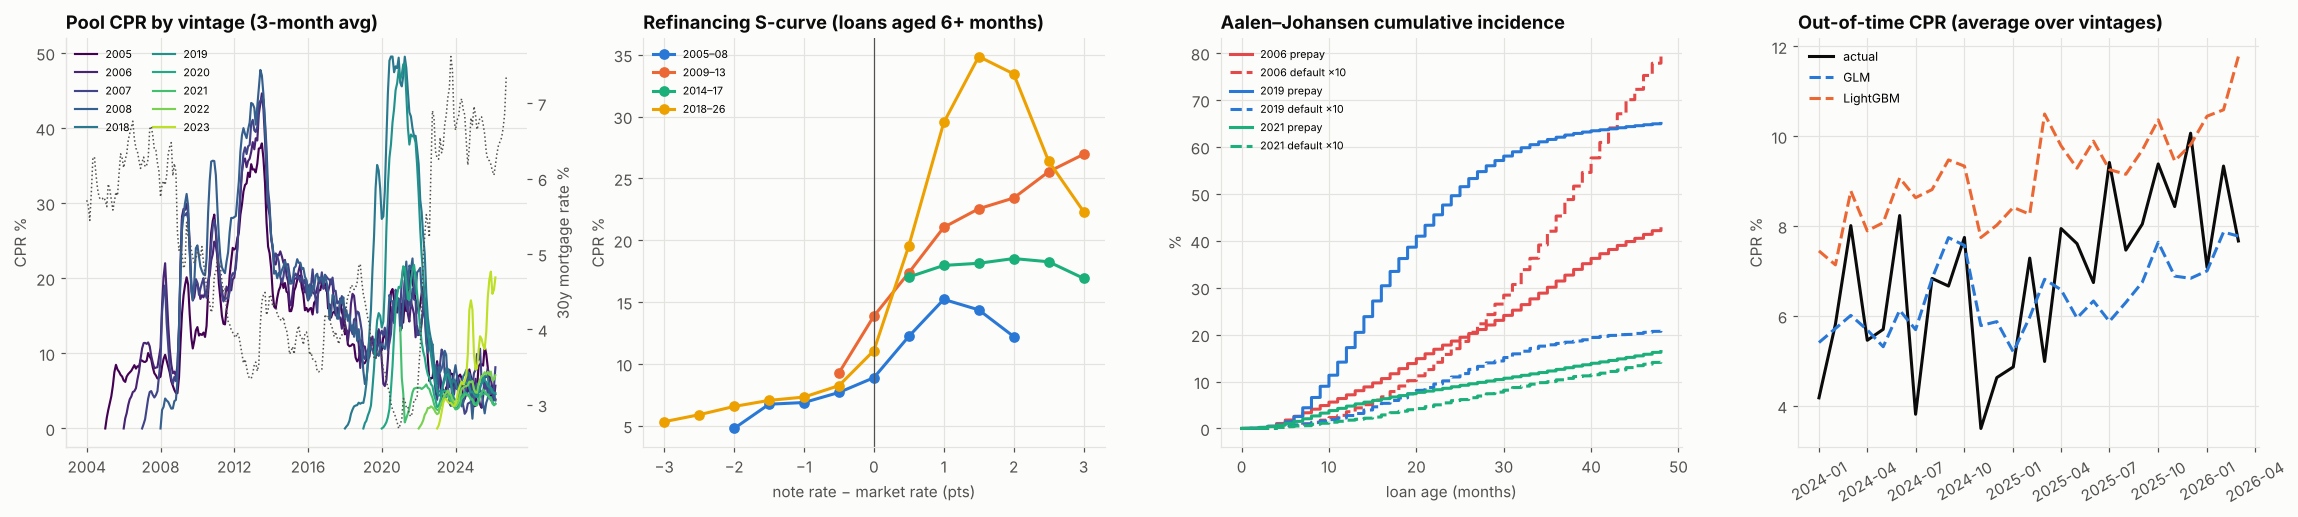

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
ax = axes[0]
for (v, g_), col in zip(pool.groupby("vintage"), plt.cm.viridis(
        np.linspace(0, 0.9, pool["vintage"].nunique()))):
    ax.plot(
        g_["date"],
        g_["CPR %"].rolling(3, min_periods=1).mean(),
        color=col,
        lw=1.4,
        label=str(v),
    )
ax2 = ax.twinx()
ax2.plot(mort.index, mort.values, color=INK_2, ls=":", lw=1)
ax2.set_ylabel("30y mortgage rate %", color=INK_2)
ax2.grid(False)
ax.set_title("Pool CPR by vintage (3-month avg)")
ax.set_ylabel("CPR %")
ax.legend(fontsize=7, ncol=2)
ax = axes[1]
for (per_, g_), col in zip(scurve_era.groupby("period"), PALETTE):
    ax.plot(g_["incentive"], g_["CPR %"], "o-", color=col, label=per_)
ax.legend(fontsize=7)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_title("Refinancing S-curve (loans aged 6+ months)")
ax.set_xlabel("note rate − market rate (pts)")
ax.set_ylabel("CPR %")
ax = axes[2]
for v, col in zip([2006, 2019, 2021], [PALETTE[7], PALETTE[0], PALETTE[2]]):
    if (v, "prepay") in cif_curves:
        c_ = cif_curves[(v, "prepay")]
        ax.plot(c_.index, c_.values * 100, color=col, label=f"{v} prepay")
        d_ = cif_curves[(v, "default")]
        ax.plot(
            d_.index,
            d_.values * 100 * 10,
            color=col,
            ls="--",
            label=f"{v} default ×10",
        )
ax.set_title("Aalen–Johansen cumulative incidence")
ax.set_xlabel("loan age (months)")
ax.set_ylabel("%")
ax.legend(fontsize=7)
ax = axes[3]
tot = res.groupby(level="per").mean()
xs = pd.to_datetime(tot.index.astype(str), format="%Y%m")
ax.plot(xs, tot["actual CPR"], color=INK, label="actual")
ax.plot(xs, tot["GLM CPR"], color=PALETTE[0], ls="--", label="GLM")
ax.plot(xs, tot["LightGBM CPR"], color=PALETTE[1], ls="--", label="LightGBM")
ax.set_title("Out-of-time CPR (average over vintages)")
ax.set_ylabel("CPR %")
ax.legend(fontsize=8)
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
save_fig(fig, "01_cpr_scurve_cif_backtest")
plt.show()

## 8. Reading the results and limitations

500,000 loans (Fannie Mae 2005–08, Freddie Mac 2018–23), monthly to March 2026:

**Two waves of prepayment, for different reasons.** The 2018 and 2019 vintages prepaid at 36–44% CPR at the 2020–21 trough in mortgage rates; by 2023 every recent vintage had slowed to 4–6% CPR. The crisis vintages peaked later and lower: 30–41% CPR in 2012–13, when rates finally fell below 4% and government refinancing programmes let underwater borrowers refinance. The 2023 vintage, originated at 6.6%, is now the fastest (20% CPR in 2026) because rates fell below its note rate in 2025.

**The crisis in one row.** Default rates (CDR) of the 2006 and 2007 vintages reached 7–8% a year in 2009–10 and stayed above 4% until 2013; the 2005 and 2008 vintages peaked at 4–5%. The worst year of any recent vintage is 3.5% (2018 vintage, 2021), mostly forbearance exits.

**The S-curve depends on whether borrowers *can* refinance.** Since 2018, speeds go from 5–8% CPR out of the money to 30% at +1 point and a peak of 35% at +1.5, then fall (22% at +3) as the remaining high-incentive loans are the ones that did not refinance. In 2009–13 the same +1 point produced only 21% CPR and +2 points 23%: falling house prices left many borrowers without the equity to refinance, and lenders had tightened. Before the crisis (2005–08) speeds at +1 point were 15%. An S-curve fitted on one period does not transfer to another.

In the pooled GLM the incentive adds +0.44 per point, +0.28 more above 0.5 point and −0.65 above 1.5 points; larger loans prepay faster (+0.30 per log point of balance), and so do higher credit scores (+0.16 per 50 points), the borrowers lenders were still willing to refinance.

**Ignoring the competing risk overstates default, most where prepayment is fast.** Four-year cumulative default is 11.9% for the 2007 vintage by Aalen–Johansen and 16.8% by 1 − Kaplan–Meier (+41%); 2006 and 2008 are overstated by 44% and 51%. For the fast-prepaying 2018 vintage the overstatement is 117% (2.2% against 4.8%). For prepayment the bias is only 1–8%.

**Out of time the two models tie.** On 2024 Q1 – 2026 Q1 the GLM's monthly CPR by vintage has a mean absolute error of 4.7 points with almost no bias (−0.5); LightGBM has the same error but over-predicts by 2.2 points. Training on the crisis years, when many in-the-money borrowers could not refinance, removed the GLM's earlier over-prediction of speeds for today's locked-in borrowers. Defaults are predicted well by both (CDR bias −0.2 points; loan-month AUC 1.0), driven by last month's delinquency (+4.6 log-odds after a 30-day delinquency, +10.7 after 60 days).

**Negative convexity in one table.** For the loans active in March 2026 (mortgage rate 6.18%), the GLM's 12-month prepayment probability is 7.8%. It rises to **12.0%** if rates fall 100 bp and drops to **4.9%** if they rise 100 bp. The 2023 vintage swings from 11% to 27%; the 2020–21 vintages, at 3%, from 1.8–2.0% to 4.3–4.7%.

An MBS holder (or a lender funding this book with fixed-rate debt) gets money back faster exactly when reinvestment rates are lower.

**Limitations**

- Speeds are measured on a 1-in-10 loan sample for the models and on the full sample for pools. The sample files are not the agencies' full populations, so pool speeds are indicative, not those of any traded MBS.
- The crisis loans are Fannie Mae acquisitions (prime and Alt-A, no subprime); the two periods also come from different agencies.
- Curtailments (partial prepayments) are not separated from scheduled amortisation; CPR here counts full payoffs only.
- The hazard models have no house-price or credit-availability variable, which is why the crisis-era S-curve has to be read from the data rather than from the model; the rate-shock projection holds the shock flat for 12 months.

In [10]:
summary.to_csv(OUT_DIR / "cpr_cdr_by_vintage_year.csv")
scurve.to_csv(OUT_DIR / "s_curve.csv", index=False)
scurve_era.to_csv(OUT_DIR / "s_curve_by_period.csv", index=False)
cif_tab.to_csv(OUT_DIR / "competing_risks_incidence.csv")
coef.to_csv(OUT_DIR / "hazard_coefficients.csv")
err.to_csv(OUT_DIR / "out_of_time_errors.csv")
shock_tab.to_csv(OUT_DIR / "rate_shock_prepayment.csv")
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_cpr_scurve_cif_backtest.png, competing_risks_incidence.csv, cpr_cdr_by_vintage_year.csv, hazard_coefficients.csv, out_of_time_errors.csv, rate_shock_prepayment.csv, s_curve.csv, s_curve_by_period.csv


## References

### Finance and regulation

- Schwartz, E. S., & Torous, W. N. (1989). Prepayment and the valuation of mortgage-backed securities. *The Journal of Finance, 44*(2), 375–392. https://doi.org/10.1111/j.1540-6261.1989.tb05062.x
- Deng, Y., Quigley, J. M., & Van Order, R. (2000). Mortgage terminations, heterogeneity and the exercise of mortgage options. *Econometrica, 68*(2), 275–307. https://doi.org/10.1111/1468-0262.00110
- Richard, S. F., & Roll, R. (1989). Prepayments on fixed-rate mortgage-backed securities. *The Journal of Portfolio Management, 15*(3), 73–82. https://doi.org/10.3905/jpm.1989.409207
- Fabozzi, F. J. (Ed.). (2016). *The handbook of mortgage-backed securities* (7th ed.). Oxford University Press. https://doi.org/10.1093/acprof:oso/9780198785774.001.0001
- Fannie Mae. (2026). *Single-Family Loan Performance Data* [Data set]. https://capitalmarkets.fanniemae.com/credit-risk-transfer/single-family-credit-risk-transfer/fannie-mae-single-family-loan-performance-data

### Machine learning and deep learning

- Fine, J. P., & Gray, R. J. (1999). A proportional hazards model for the subdistribution of a competing risk. *Journal of the American Statistical Association, 94*(446), 496–509. https://doi.org/10.1080/01621459.1999.10474144
- Kaplan, E. L., & Meier, P. (1958). Nonparametric estimation from incomplete observations. *Journal of the American Statistical Association, 53*(282), 457–481. https://doi.org/10.1080/01621459.1958.10501452
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html